# Hierarchical clustering / التجميع الهرمي

Run the cells in order with **Shift + Enter**. The CSV has 30 made-up points, two coordinates on the same scale, and no labels. It is original to AI Visual and released under CC0 1.0.

شغّل الخلايا بالترتيب باستخدام **Shift + Enter**. يحتوي الملف على 30 نقطة اصطناعية بإحداثيَين على المقياس نفسه ومن دون تسميات. البيانات من إعداد AI Visual ومنشورة بموجب CC0 1.0.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/clustering_points.csv"
X = pd.read_csv(url)[["x", "y"]].to_numpy()
X[:5]

array([[0.5776 , 0.78424],
       [0.52881, 0.70383],
       [0.25844, 0.32205],
       [0.22855, 0.35964],
       [0.69219, 0.25466]])

## Build the tree / ابنِ الشجرة

Ward linkage merges the pair of groups that increases squared spread the least. Use scikit-learn to get three groups, then SciPy to draw the full Ward tree. The last few rows show the highest joins.

تدمج طريقة Ward المجموعتين اللتين تضيفان أقلّ زيادة إلى مجموع مربّعات المسافات إلى المراكز. استخدم scikit-learn للحصول على ثلاث مجموعات، ثم SciPy لرسم الشجرة كاملة. تُظهر الصفوف الأخيرة أعلى الوصلات.

In [2]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
merges = linkage(X, method="ward")
print(pd.Series(labels).value_counts().sort_index())
print(merges[-4:])

0    10
1    10
2    10
Name: count, dtype: int64
[[45.         53.          0.17945886 10.        ]
 [46.         52.          0.19811539 10.        ]
 [54.         56.          1.64799501 20.        ]
 [55.         57.          1.80959944 30.        ]]


## See it / شاهد النتيجة

The dashed line is your cut. Count its intersections with vertical branches, then compare with the number of colours in the scatter. Change `cut` to `0.10` or `1.4` and rerun this cell.

الخطّ المتقطّع هو خطّ القطع. عدّ تقاطعاته مع الفروع العمودية، ثم قارنها بعدد الألوان في رسم النقاط. غيّر `cut` إلى `0.10` أو `1.4` وأعد تشغيل هذه الخلية.

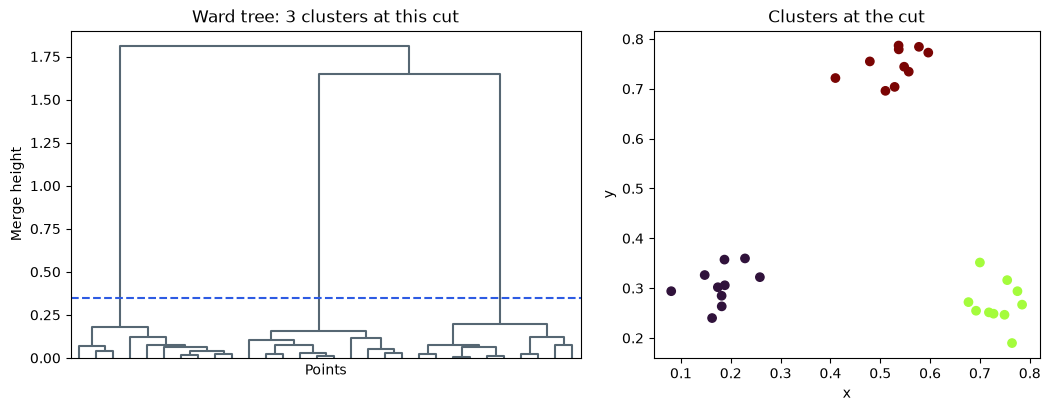

In [3]:
cut = 0.35
groups = fcluster(merges, t=cut, criterion="distance")
count = len(set(groups))
fig, (tree, scatter) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
dendrogram(merges, ax=tree, no_labels=True, link_color_func=lambda node: "#566773")
tree.axhline(cut, color="#2d5be3", linestyle="--")
tree.set(title=f"Ward tree: {count} clusters at this cut", xlabel="Points", ylabel="Merge height")
scatter.scatter(X[:, 0], X[:, 1], c=groups, cmap="turbo")
scatter.set(title="Clusters at the cut", xlabel="x", ylabel="y", aspect="equal")
plt.show()